# Simulating an M+1 experiment

The first step in using this code is to set up a hypothetical experiment and check to see if it can recover the site-specific values you care about. Even if you already have experimental data, it is essential to do this to understand the system and how the code can be used to help. It will also show the precision you can expect with your experimental design. This tutorial shows how to do this, using alanine from Weiss et al. 2023 as a model. 

Specifically, this tutorial will:

1. Build a model of alanine.
2. Examine its predicted spectrum.
3. Simulate a full sample/standard comparison, using user-defined input values for both sample and standard.
4. Apply the M+1 algorithm to these data to recover the site-specific values.

This will demonstrate both which sites are constrained and how precisely they are constrained. 

The example follows the alanine measurements of Weiss et al. (2023); the method is described in
Csernica and Eiler (2023). See the [README](https://github.com/Csernica/isotomics#citation) for
full citations.

In [1]:
from importlib import resources

import pandas as pd
import matplotlib.pyplot as plt

from isotomics import readCSVAndSimulate as sim
from isotomics import spectrumVis

# Example inputs bundled with the package
DATA = resources.files("isotomics") / "input_data"
MOLECULE_INPUT_PATH = str(DATA / "Example_Molecule_Input.csv")

## 1. Describe the molecule

To define a molecule, we construct a .csv file giving details about the molecule. The alanine .csv is bundled with the package; its location is stored in `MOLECULE_INPUT_PATH` above.

The .csv file has one row per **site** where a site is a group of atoms of the same element which are treated as isotopically equivalent (see Csernica and Eiler 2023). For example, three methyl hydrogens may correspond to the same site as they are indistinguishable. We can also treat atoms which are (in principle) distinguishable, such as alpha and beta carbons, as part of the same site when our experimental design cannot distinguish these. 

The .csv file also includes the number of atoms in a site, and information about how that site is sampled upon fragmentation. This is done by providing whether a site is retained ('1') or lost ('0') upon fragmentation. Importantly, **there is no way for a site to be partially retained or lost**, which may force us to split atoms which we would intuitively combine. For example, if there is a set of 3 methyl hydrogens, and 2 of these are lost but one retained to form a given fragment, we cannot input 1/3 to a methyl site with 3 hydrogens; we must instead define two sites (H_methyl_retained and H_methyl_lost, for example), and then give them values of '1' and '0' for the corresponding fragment.

You will have to trust that this unintuitive treatment has some nice benefits in calculation elsewhere. 

Finally, we have a 'full' fragment; in a certain sense this is not a 'fragment' of the molecule, but mathematically it is equivalent (it is a special case of a 'fragment' with all sites retained) and so we use the same nomenclature. This should only be included when we observe the intact molecule. 



:::{note}
**Fragments formed by more than one pathway.** Sometimes the same fragment ion forms by several
pathways that retain different sites. In that case, give the fragment one column per pathway
(`Fragment 82_01`, `Fragment 82_02`, …) and add a final row named `Relative Contribution` giving
the share of the fragment formed by each pathway. Each pathway becomes a *subgeometry* of the
fragment. Each fragment in the alanine example forms by a single pathway, so its .csv has neither.
See *Fragments formed by more than one pathway* at the end of this tutorial for a full example.
:::

In [2]:
molecule = pd.read_csv(MOLECULE_INPUT_PATH, index_col="Site Names")
molecule[["Element", "Number Atoms", "Fragment full", "Fragment 44"]]

,Element,Number Atoms,Fragment full,Fragment 44
Site Names,,,,
Calphabeta,C,2,1,1
Ccarboxyl,C,1,1,0
Ocarboxyl,O,2,1,0
Namine,N,1,1,1
Hretained,H,6,1,1
Hlost,H,2,1,0


Here alanine is split into six sites. The `44` fragment retains the α and β carbons, the amine
nitrogen and six of the hydrogens, but loses the carboxyl group and two hydrogens. 

## 2. Predict the spectrum of the standard

With our csv thus defined, we next define a set of delta values, read the csv with these delta values to initialize a molecule with a specific isotopic structure  using `moleculeFromCsv`, and simulate a measurement using `simulateMeasurement`. This is an ideal measurement with no
instrument fractionation. Site δ values are always
given in the same order as the CSV rows.

In [3]:
# The natural-abundance alanine standard of Weiss et al. (2023), Table 2: Calphabeta is the mean of C-2 (-12.9)
# and C-3 (-7.0), Ccarboxyl is C-1 (-11.9)
STD_DELTAS = [-9.95, -11.9, 0, 0, 0, 0]  # Calphabeta, Ccarboxyl, Ocarboxyl, Namine, Hretained, Hlost

initializedMolecule = sim.moleculeFromCsv(MOLECULE_INPUT_PATH, deltas=STD_DELTAS)
predictedMeasurement, MNDict, _ = sim.simulateMeasurement(initializedMolecule, massThreshold=5)

`initializedMolecule` contains the basic information about the molecule--the table we just entered as a csv (molecularDataFrame), as well as various depictions of the fragments. These include both a "site" description of fragmentation, showing which sites are retained and lost, and an "atom" description, which expands each site to its constituent atoms and then tracks fragmentation. 

In [4]:
initializedMolecule

{'molecularDataFrame':            IDS  Number  Fragment full Fragment 44  deltas
 Calphabeta   C       2              1           1   -9.95
 Ccarboxyl    C       1              1           x  -11.90
 Ocarboxyl    O       2              1           x    0.00
 Namine       N       1              1           1    0.00
 Hretained    H       6              1           1    0.00
 Hlost        H       2              1           x    0.00,
 'expandedFrags': [[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
  [1, 1, 'x', 'x', 'x', 1, 1, 1, 1, 1, 1, 1, 'x', 'x']],
 'fragSubgeometryKeys': ['full_01', '44_01'],
 'fragmentationDictionary': {'full': {'01': {'subgeometry': [1, 1, 1, 1, 1, 1],
    'relCont': 1}},
  '44': {'01': {'subgeometry': [1, 'x', 'x', 1, 1, 'x'], 'relCont': 1}}}}

`initializedMolecule` is a dictionary with four entries:

- `molecularDataFrame`: the .csv giving details about the molecule. 
- `fragmentationDictionary`: for each fragment, specifies a **site** depiction which has one entry per site. Can include multiple subgeometries for fragments formed via multiple pathways, and specifies the relative contribution of each. Each fragment
  here has a single subgeometry; see the end of the tutorial for more details regarding molecules where fragments have multiple subgeometries. 
- `expandedFrags`: an **atom** depiction of each subgeometry, formatted as a list for easier parsing later on. Alanine has 14 atoms across 6 sites, so each vector has 14 entries.
- `fragSubgeometryKeys`: names for each subgeometry (`full_01`, `44_01`), in the same order as
  `expandedFrags`.

`predictedMeasurement` is a dictionary containing the predicted observations. It has one entry per mass selection
(`M0` to `M5` here, set by `massThreshold`) plus `U Values`:

In [5]:
print(predictedMeasurement.keys())
predictedMeasurement['M1']

dict_keys(['M0', 'M1', 'M2', 'M3', 'M4', 'M5', 'U Values'])


{'full': {'2H': {'Abs. Abundance': np.float64(0.0011940138053709646),
   'Rel. Abundance': np.float64(0.03206063362358951),
   'Combined Rel. Abundance': np.float64(0.03206063362358951),
   'Adj. Rel. Abundance': np.float64(0.03206063362358951)},
  '15N': {'Abs. Abundance': np.float64(0.003522402051668967),
   'Rel. Abundance': np.float64(0.09458051585798267),
   'Combined Rel. Abundance': np.float64(0.09458051585798267),
   'Adj. Rel. Abundance': np.float64(0.09458051585798267)},
  '17O': {'Abs. Abundance': np.float64(0.0007280525241724921),
   'Rel. Abundance': np.float64(0.019549041335390434),
   'Combined Rel. Abundance': np.float64(0.019549041335390434),
   'Adj. Rel. Abundance': np.float64(0.019549041335390434)},
  '13C': {'Abs. Abundance': np.float64(0.03179789617681164),
   'Rel. Abundance': np.float64(0.8538098091830374),
   'Combined Rel. Abundance': np.float64(0.8538098091830374),
   'Adj. Rel. Abundance': np.float64(0.8538098091830374)}},
 '44': {'Unsub': {'Abs. Abundance':

Within a mass selection there is one entry per fragment, and within that one entry per
**isotopic peak**, (`13C`, `15N`, `2H`, …). For the M+1 measurement
of fragment 44:

In [6]:
pd.DataFrame(predictedMeasurement["M1"]["44"]).T

,Abs. Abundance,Rel. Abundance,Combined Rel. Abundance,Adj. Rel. Abundance
Unsub,0.011612,0.311794,0.311794,0.311794
2H,0.000896,0.024045,0.024045,0.024045
15N,0.003522,0.094581,0.094581,0.094581
13C,0.021213,0.569580,0.569580,0.569580


Note the `Unsub` peak. When the molecule in a M+1 experiment loses its rare substitution upon fragmentation, then it results in an unsubstituted peak. For example, for alanine this may occur in fragment 44 when the parent molecule had a ¹³C substitution at the carboxyl carbon. 

Each peak has four abundances, which apply successive steps of the measurement model:

- `Abs. Abundance`: the absolute abundance of all molecules that end up in this peak. The sum of all instances of the parent molecule, including the unsubstituted molecule, is equal to 1. Most of this material is rejected by the M+1 mass selection. For example, the abs. abundance of ¹³C in the 44 fragment is ~2%, as there are two carbons present, each with abundance of about 1% in the parent molecule. 
- `Rel. Abundance`: normalized so the peaks of this fragment sum to 1. That is, the denominator is the sum  of the abundances of all M+1 substituted isotopologues. These are the
  **M+N relative abundances** the method works with.
- `Combined Rel. Abundance`: The same, after merging peaks the instrument cannot resolve; this would often be the case with substitutions such as ¹³C and ¹⁷O. Such unresolved peaks are not present in this workflow; see *Unresolved and unobserved peaks* below for an example.
- `Adj. Rel. Abundance`: The combined rel. abundance, after removing peaks which are not observed due to their low abundance and renormalizing. For example, if some ²H peaks are not observed because they are too low in abundance, then we remove the corresponding abundance and renormalize. Again, this is not the case for our example, so Adj. Rel. Abundance == Rel. Abundance. **This is the quantity that is actually observed via the Orbitrap**. 

See below for more details. 

Finally, the predictedMeasurement dictionary contains `U Values` which are molecular-average ratios. For example, $U^{^{13}\mathrm{C}}$ is a ratio. The numerator is the sum of the concentrations of all isotopologues with a single ¹³C substitution. The denominator is the concentration of the unsubstituted isotopologue.

In [7]:
pd.Series(predictedMeasurement["U Values"])[["13C", "15N", "17O", "18O", "2H"]]

13C    0.033184
15N    0.003676
17O    0.000760
18O    0.004010
2H     0.001246
dtype: float64

### Unresolved and unobserved peaks

There are two main ways that peaks can be unobserved. Both present a challenge for M+1 relative abundance measurements, where the denominator sums across all isotopic peaks. These are 

- 1: Unresolved peaks. This occurs when two peaks are very close to each other and therefore merge; this is often the case, for example, with ¹³C and ¹⁷O. 
- 2: Low abundance peaks. This occurs when a peak has very low abundance and is not observed by the mass spectrometer. This often occurs for ²H and many multiply-substituted peaks. 

The code has two ways of dealing with these:

- `omitMeasurements` removes low abundance peaks, and may be set as, e.g.: `{"M1": {"full": ["17O"]}}`.
- `unresolvedDict` accounts for unresolved peaks by adding the abundance of one peak to another. For example, if ¹⁷O and ¹³C are unresolved, it adds the ¹⁷O abundance to the ¹³C peak. This could be entered as:  `{"M1": {"full": {"17O": "13C"}}}`.

Here is the M+1 measurement of the full molecule with ¹⁷O omitted (fragment 44 has no ¹⁷O peak,
since it loses the only oxygen site):

In [8]:
omitted, _, _ = sim.simulateMeasurement(initializedMolecule, omitMeasurements={"M1": {"full": ["17O"]}})
pd.DataFrame(omitted["M1"]["full"]).T

,Abs. Abundance,Rel. Abundance,Combined Rel. Abundance,Adj. Rel. Abundance
2H,0.001194,0.032061,0.032061,0.032700
15N,0.003522,0.094581,0.094581,0.096466
13C,0.031798,0.853810,0.853810,0.870834


and with ¹⁷O unresolved from ¹³C:

In [9]:
unresolved, _, _ = sim.simulateMeasurement(initializedMolecule, unresolvedDict={"M1": {"full": {"17O": "13C"}}})
pd.DataFrame(unresolved["M1"]["full"]).T

,Abs. Abundance,Rel. Abundance,Combined Rel. Abundance,Adj. Rel. Abundance
2H,0.001194,0.032061,0.032061,0.032061
15N,0.003522,0.094581,0.094581,0.094581
13C,0.031798,0.853810,0.873359,0.873359


In both cases `Rel. Abundance` is the same as without either option: it describes all of the M+1
ions, including the ¹⁷O peak. In the **omitted** case, `Combined Rel. Abundance` is unchanged as there are no unresolved peaks, but `Adj. Rel. Abundance` increases, as it renormalizes the observed peaks in the absence of the missing ¹⁷O peak. In the **unresolved** case, `Combined Rel. Abundance` adds the ¹⁷O abundance to the ¹³C peak
  (0.8538 + 0.0195 ≈ 0.8734). In this case, the normalization includes all of the isotopic abundance, so  `Adj. Rel. Abundance` equals `Combined Rel. Abundance`.

The instrument observes only `Adj. Rel. Abundance`. 

`MNDict` tracks the underlying **isotopologues**. For each mass selection it lists every
isotopologue, keyed by a string with one character per atom (in the order of the sites, so 14
characters for alanine), along with its concentration and fragmentation geometries:

In [10]:
pd.DataFrame(MNDict["M1"]).T

,Number,Full,Conc,Mass,Subs,Stochastic U,full_01 Identity,full_01 Subs,44_01 Identity,44_01 Subs
00000000000001,2,"(0, 0)0(0, 0)0(0, 0, 0, 0, 0, 0)(0, 1)",0.000299,1,2H,0.000312,00000000000001,2H,00xxx0000000xx,Unsub
00000000000100,6,"(0, 0)0(0, 0)0(0, 0, 0, 0, 0, 1)(0, 0)",0.000896,1,2H,0.000935,00000000000100,2H,00xxx0000001xx,2H
00000100000000,1,"(0, 0)0(0, 0)1(0, 0, 0, 0, 0, 0)(0, 0)",0.003522,1,15N,0.003676,00000100000000,15N,00xxx1000000xx,15N
00001000000000,2,"(0, 0)0(0, 1)0(0, 0, 0, 0, 0, 0)(0, 0)",0.000728,1,17O,0.00076,00001000000000,17O,00xxx0000000xx,Unsub
00100000000000,1,"(0, 0)1(0, 0)0(0, 0, 0, 0, 0, 0)(0, 0)",0.010585,1,13C,0.011047,00100000000000,13C,00xxx0000000xx,Unsub
01000000000000,2,"(0, 1)0(0, 0)0(0, 0, 0, 0, 0, 0)(0, 0)",0.021213,1,13C,0.022138,01000000000000,13C,01xxx0000000xx,13C


- `Number`: how many equivalent isotopologues this row stands for (e.g. a ¹³C on either of the
  two α/β carbons).
- `Full`: a somewhat expanded representation, where multi-atomic sites are represented as tuples. 
- `Conc`: concentration, as a fraction of all molecules.
- `Mass`: its nominal mass shift (1 for M+1).
- `Subs`: the substitution it carries.
- `Stochastic U`: its abundance relative to the unsubstituted molecule.
- `<fragment> Identity` and `<fragment> Subs`: the fragment ion it forms (`x` marks lost atoms)
  and the substitution that ion carries, i.e. which peak it contributes to.

We can also visualize the full mass spectrum from here. (Technically it is plotting the U values, normalized to a concentration of 1, but this gives correct relative abundances). The full-molecule spectrum shows the unsubstituted peak and every isotopologue up to M+5 (set by massThreshold, above). 

Obviously the xticks get very messy with so many peaks. There are two ways to deal with this: first, manually zoom in using the xlim parameter to focus on a region of interest. Second, suppress low  abundance peaks using the lowAbundanceCutOff parameter. 

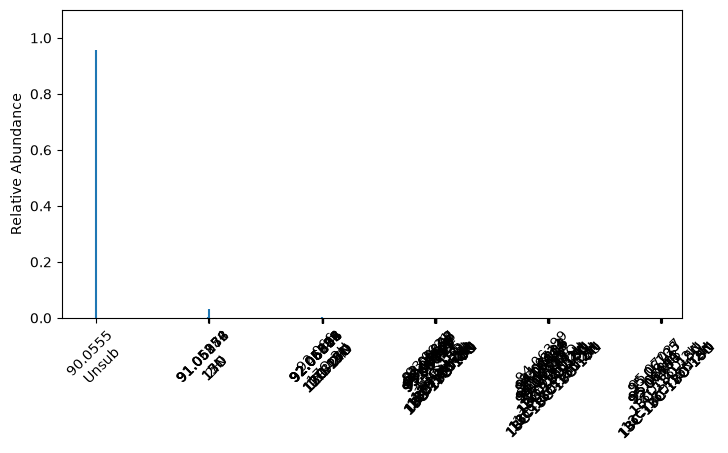

In [11]:
spectrumVis.fullSpectrumVis(
    predictedMeasurement["U Values"],
    initializedMolecule["molecularDataFrame"],
    figsize=(8, 4), xlim = (89.75,95.25), ylim = (0, 1.1), lowAbundanceCutOff=1e-10, logY = False
)

More valuably, this allows us to visualize the spectra we get via M+N measurements of a compound, which we can compare to experiment to see if we get (roughly) the right results. Here is the M+1 experiment for the 44 fragment of alanine, which shows how abundance is distributed among the unsubstituted, ¹³C, ¹⁵N and ²H peaks.

We have to do this one fragment at a time because there is no data here to account for different fragment abundances; for example, fragment 44 may be less abundant than fragment full, even if they are observed simultaneously in a M+1 experiment. (It may be fun and instructive to explore how the spectrum evolves using "M2", "M3", or "M4" as inputs)

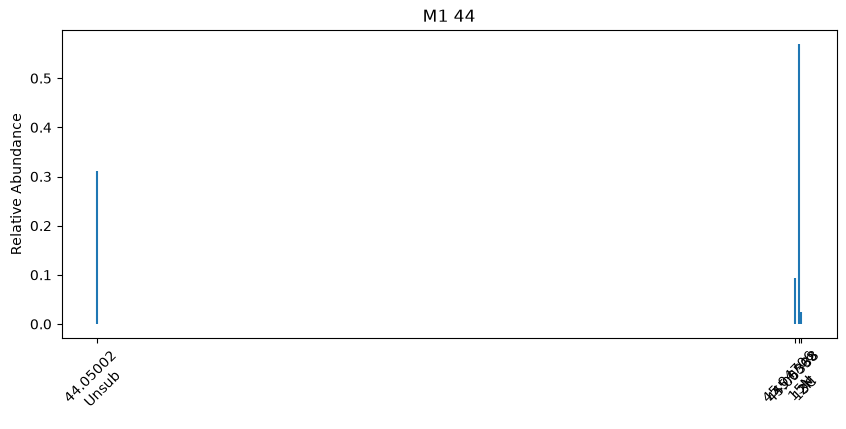

In [12]:
spectrumVis.MNSpectrumVis(
    initializedMolecule["molecularDataFrame"], "44", predictedMeasurement, "M1", MNDict, logY = False, lowAbundanceCutOff=1e-10, 
)

:::{tip}
Pass `outputIsotopologs=True` to either plotting function to also write an `isotopologs.tsv`
listing these peaks, which you can use to set up data processing in IsoX.
:::

## 3. Simulate a sample/standard comparison

With the ability to simulate one spectrum in hand, we will next simulate a sample/standard comparison. To do so, we need 
**three** sets of δ values:

- `STD_DELTAS`: the *true* composition of the standard. The simulation uses this to generate the
  standard's measurement.
- `SMP_DELTAS`: the *true* composition of the sample.
- `STANDARD_DELTA_APPROX`: what *you believe* the standard's composition is. Often, this will be unknown; for example, a user may purchase a commercial compound and adopt it as an in-house standard, with only a rough guess of its isotopic composition. This value may differ from the true composition. Setting this separately from STD_DELTAS allows us to explore how much error will be induced by our imperfect knowledge of the standard. 

In [13]:
# True compositions: the Weiss et al. (2023) standard, and their sample C-1a, which is -0.8 per mil (Calphabeta)
# and +32.0 per mil (Ccarboxyl) relative to that standard
STD_DELTAS = [-9.95, -11.9, 0, 0, 0, 0]
SMP_DELTAS = [-10.742, 19.719, 0, 0, 0, 0]
STANDARD_DELTA_APPROX = [-8.95, -10.9, 10, -5, 20, 20] #offset by 1 per mil in 13C from the true STD_Deltas, and with some additional errors for demonstration.  

Next, we describe how good our mass spectrometry measurement is. This is set by an error file, `Alanine Experimental Errors.csv`, bundled with the package (its location is `ERROR_PATH` below). Errors are given as fractions; e.g., 0.001 means 1 ‰. 

Note that here, we are using a "molecular average" value from EA-IRMS, which has a very tight error of 0.1 ‰, as was done in Weiss et al. 2023. 

In [14]:
ERROR_PATH = str(DATA / "Alanine Experimental Errors.csv")
print((DATA / "Alanine Experimental Errors.csv").read_text(encoding="utf-8-sig"))

Molecular Average,Relative Error
13C/Unsub,0.0001
Fragment full,M+1 Relative Abundance Error
2H,0.005
15N,0.002
13C,0.001
17O,0.005
Fragment 44,M+1 Relative Abundance Error
Unsub,0.001
2H,0.005
13C,0.001
15N,0.002



We are now ready to run the experiment. There are a few additional parameters that are worth noting in this simulation:

- `omitMeasurements` removes ion beams that are not observed. Here we remove the ¹⁷O peak of the
  full molecule; below, we compare this with treating ¹⁷O as unresolved from ¹³C.
- `calcFF` and `ffstd` add random instrumental fractionation to every ion beam (here σ = 1 %). Specifically, the algorithm chooses a fractionation factor for each observed peak, from a normal distribution centered around 1 and with a standard deviation of ffstd. It then applies this fractionation factor to both sample and standard (prior to normalization). This tests whether or not the use of sample/standard comparisons can account for instrument fractionation. 
- `UMNSub` (default `"13C"`, i.e. ¹³C/Unsub) chooses which molecular-average ratio is used to convert M+1 relative abundances into site-specific values. In general, it is best to use whichever molecular-average value has the smallest relative error, which will typically be from an EA-IRMS measurement. Its error (0.1 ‰) comes from the `Molecular Average` section of the error file.
- `perturbTheoryOAmt` We account for lost abundance (from unresolved and unobserved peaks) via a correction factor; the details are somewhat involved, so we direct the reader to Csernica and Eiler 2023, including the supplement, for details. It becomes more important as more peaks are unobserved, which is more common in M+2, M+3, and so on, experiments. For a M+1 case where all peaks are observed, it can be ignored. 

Then `simulateSmpStd` simulates both measurements, solves them with the M+1 Monte Carlo routine
and plots the recovered sample composition relative to the standard.

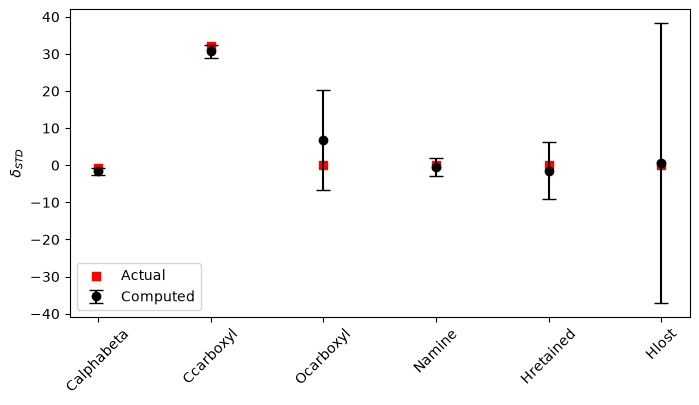

In [15]:
simulationOutput = sim.simulateSmpStd(
    MOLECULE_INPUT_PATH,
    STD_DELTAS,
    SMP_DELTAS,
    STANDARD_DELTA_APPROX,
    UMNSub="13C",
    omitMeasurements={"M1": {"full": ["17O"]}},
    calcFF=True,
    ffstd=0.01,
    perturbTheoryOAmt = 0.000,
    errorPath=ERROR_PATH,
    resultsFileName="molecular_model_output.csv",
)

The results here are output as $\delta_{STD}$, i.e., the delta values of the sample compared to the standard. The above plot gives an idea of the accuracy and precision we get from this experimental design. Intriguingly, even with the ¹⁷O peak not observed directly, the ¹⁷O parameter is somewhat constrained; this is due to the 'closure' constraint of M+1 relative abundance space, which dictates that all M+1 relative abundances must sum to 1. Likewise, we can see relatively tight bounds on the carbon and nitrogen isotopes, somewhat worse on the retained hydrogens, and quite poor error bars on the hydrogens which are lost during fragmentation. 

It is somewhat in the weeds here, but the ¹⁷O value interacts particularly strongly with perturbTheoryOAmt. Briefly, perturbTheoryOAmt sets the error on our approximation of the total sum of the M+1 relative abundances, and therefore has a powerful effect on ¹⁷O, which is constrained only by this sum. Note that including a larger value for perturbTheoryOAmt (e.g., 0.002) has a profound effect on the recovered precision for ¹⁷O, and a real (but less profound) effect on the remaining error bars. At this point, we just suggest that the user be aware of this dynamic, and direct the user to Csernica and Eiler 2023, especially the supplement, for additional discussion. 

We can also access the values directly. Below, they are given in two forms: as "relative deltas" and as "CRF Deltas". 

The "relative deltas" are what is plotted above, giving the delta values of the sample relative to our working standard. The "CRF deltas" instead give the delta values compared to the 'combined reference frame', which means a common reference for each element: VPDB for ¹³C, VSMOW for ¹⁷O, AIR for ¹⁵N, and VSMOW for ²H. These are calculated *assuming* the values in STANDARD_DELTA_APPROX are accurate--if they are not, then the numbers are not meaningful. (If they are accurate for some values in STANDARD_DELTA_APPROX but not others, then the CRF deltas are meaningful for only those values.)

In [16]:
summary = simulationOutput[["Relative Deltas", "Relative Deltas Error", "CRF Deltas", "CRF Deltas Error"]].copy()
# The true sample-vs-standard values the simulation was built from, for comparison
summary.insert(0, "True Relative Deltas",
               [((1000 + smp) / (1000 + std) - 1) * 1000 for smp, std in zip(SMP_DELTAS, STD_DELTAS)])
summary.round(2)

,True Relative Deltas,Relative Deltas,Relative Deltas Error,CRF Deltas,CRF Deltas Error
Calphabeta,-0.8,-1.65,0.89,-10.58,0.89
Ccarboxyl,32.0,30.66,1.76,19.43,1.74
Ocarboxyl,0.0,6.75,13.41,16.81,13.55
Namine,0.0,-0.49,2.31,-5.49,2.29
Hretained,0.0,-1.46,7.61,18.52,7.76
Hlost,0.0,0.56,37.72,20.57,38.48


`simulationOutput` is a table with one row per site. It also contains values from intermediate steps of the M+1 algorithm, including the M+1 relative abundances, the $U^{M+1}$ value used for scaling, and the calculated U values (e.g., $U^{^{13}\mathrm{C}}_{\alpha\beta}$) obtained by multiplying the M+1 relative abundances by $U^{M+1}$:

In [17]:
simulationOutput[["Number", "M1 M+N Relative Abundance", "UM1", "Calc U Values"]].round(5)

,Number,M1 M+N Relative Abundance,UM1,Calc U Values
Calphabeta,2,0.56410,0.03922,0.02212
Ccarboxyl,1,0.29061,0.03922,0.01140
Ocarboxyl,2,0.01970,0.03922,0.00077
Namine,1,0.09322,0.03922,0.00366
Hretained,6,0.02427,0.03922,0.00095
Hlost,2,0.00811,0.03922,0.00032


Each column has a matching `Error` column from the Monte Carlo.

### ¹⁷O omitted or unresolved?

The run above treats the ¹⁷O peak as unobserved. We could also treat ¹⁷O as an unresolved peak, which adds its abundance to the ¹³C peak:

In [18]:
unresolvedOutput = sim.simulateSmpStd(
    MOLECULE_INPUT_PATH,
    STD_DELTAS,
    SMP_DELTAS,
    STANDARD_DELTA_APPROX,
    UMNSub="13C",
    unresolvedDict={"M1": {"full": {"17O": "13C"}}},
    calcFF=True,
    ffstd=0.01,
    errorPath=ERROR_PATH,
    resultsFileName="molecular_model_output_unresolved.csv",
    plot=False,
)
pd.DataFrame({
    "True Relative Deltas": summary["True Relative Deltas"],
    "17O omitted": simulationOutput["Relative Deltas"],
    "17O unresolved": unresolvedOutput["Relative Deltas"],
    "Error (omitted)": simulationOutput["Relative Deltas Error"],
}).round(2)

,True Relative Deltas,17O omitted,17O unresolved,Error (omitted)
Calphabeta,-0.8,-1.65,-1.62,0.89
Ccarboxyl,32.0,30.66,30.61,1.76
Ocarboxyl,0.0,6.75,7.39,13.41
Namine,0.0,-0.49,-0.37,2.31
Hretained,0.0,-1.46,-1.51,7.61
Hlost,0.0,0.56,1.61,37.72


The two give nearly the same answer, in this case. 

## 4. Using your own molecule

1. Write a molecule CSV in the format above for your compound and the fragments you plan to
   observe.
2. Write an error CSV with the precision you expect for each peak.
3. Rerun this notebook with your paths and δ values.

## Fragments formed by more than one pathway

Sometimes the same fragment ion forms by several pathways that keep different sites. To specify this (distinct fragment subgeometries), you may give each subgeometry its own column, named `Fragment <name>_01`, `Fragment <name>_02`, and so on, and add a
final row named `Relative Contribution` giving the share of the fragment formed by each
pathway. The contributions must sum to 1 for each fragment. Fragments with a single column default to
1:

```text
Site Names,Element,Number Atoms,Fragment full,Fragment 82_01,Fragment 82_02
C1,C,1,1,1,0
C2,C,1,1,0,1
O1,O,1,1,1,1
Relative Contribution,,,,0.4,0.6
```

Each pathway becomes a subgeometry of the fragment in `fragmentationDictionary` (`82` → `01`,
`02`, with corresponding `relCont`). The experimental data for the
fragment still is specified as a single observation, named `82`.

The next tutorial, {doc}`m1_experimental_workflow`, solves real measurements of this alanine
system.